# Individual Assignment – Audio Analysis and AI

**Option C – Analyse an environmental sound**

Md Mohiuddin Mollah – Digital Signal Processing 2026

**Question:** Where in time and frequency is the sound event in a dog recording, and how does the spectrogram window length (512 or 2048 samples) change what can be seen?

**Data:** one dog recording, `1-100032-A-0.wav`, from the ESC-50 environmental sound dataset (category `dog`, fold 1, Freesound clip 100032). The file is 5 seconds long, mono, 44.1 kHz, 16-bit. It is converted to 16 kHz for the analysis, as the assignment requires.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.io import wavfile
from scipy.signal import resample_poly, stft
from IPython.display import Audio

AUDIO_FILE = Path('audio') / '1-100032-A-0.wav'
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

FS = 16000        # analysis sample rate (Hz)
HOP = 160         # hop length in samples (10 ms)
WINDOWS = [512, 2048]

## 1. Load the recording and convert it to 16 kHz

In [2]:
fs_orig, raw = wavfile.read(AUDIO_FILE)
x = raw.astype(np.float64) / 32768.0          # 16-bit integers to the range -1...1
if x.ndim > 1:
    x = x.mean(axis=1)                        # mono mix

# 44100 Hz * 160 / 441 = 16000 Hz (resample_poly includes an anti-aliasing filter)
y = resample_poly(x, 160, 441)
t = np.arange(len(y)) / FS

print(f'Original: {fs_orig} Hz, {raw.dtype}, {len(raw)} samples, {len(raw)/fs_orig:.2f} s')
print(f'Analysis: {FS} Hz, {len(y)} samples, {len(y)/FS:.2f} s')
print(f'Peak amplitude: {np.abs(y).max():.3f}, RMS: {np.sqrt(np.mean(y**2)):.4f}')

Original: 44100 Hz, int16, 220500 samples, 5.00 s
Analysis: 16000 Hz, 80000 samples, 5.00 s
Peak amplitude: 0.990, RMS: 0.0415


## 2. Listen

The player below plays the 16 kHz version that is analysed.

In [3]:
Audio(y, rate=FS)

## 3. Waveform and active time interval

The short-time RMS level is calculated in 10 ms frames. A frame counts as active when its level is above 10 % of the loudest frame.

Active interval: 2.27 s to 2.44 s (length 0.17 s)
Active part of the recording: 3.4 %


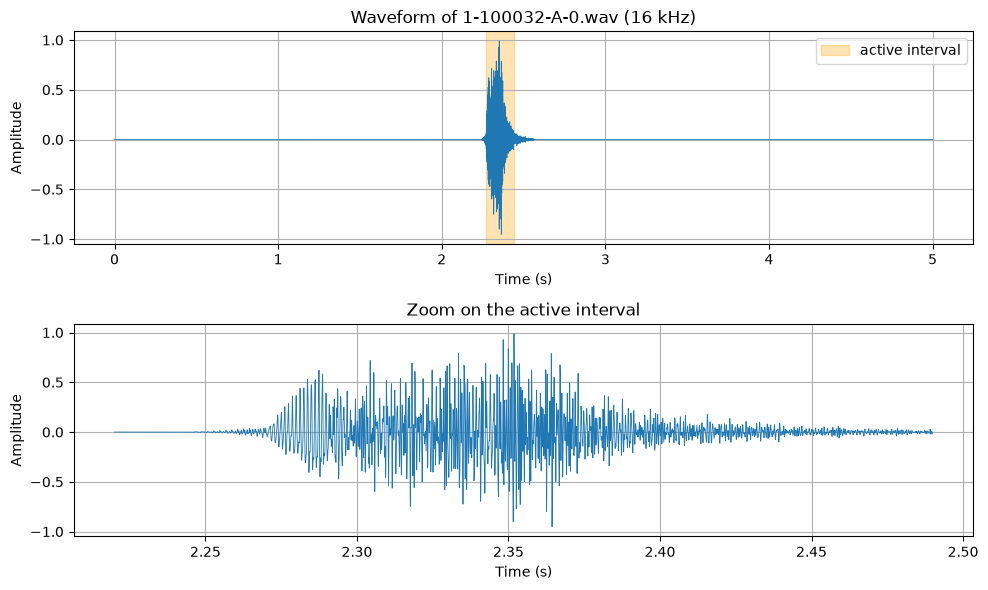

In [4]:
frames = len(y) // HOP
rms = np.sqrt(np.mean(y[:frames*HOP].reshape(frames, HOP)**2, axis=1))
active = rms > 0.1 * rms.max()

# start and end of each active stretch
edges = np.flatnonzero(np.diff(np.r_[0, active.astype(int), 0]))
intervals = edges.reshape(-1, 2) * HOP / FS
for a, b in intervals:
    print(f'Active interval: {a:.2f} s to {b:.2f} s (length {b-a:.2f} s)')
print(f'Active part of the recording: {100*active.mean():.1f} %')

t0, t1 = intervals[0][0], intervals[-1][1]

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].plot(t, y, linewidth=0.6)
ax[0].axvspan(t0, t1, color='orange', alpha=0.3, label='active interval')
ax[0].set(title='Waveform of 1-100032-A-0.wav (16 kHz)', xlabel='Time (s)', ylabel='Amplitude')
ax[0].grid(True); ax[0].legend()

zoom = (t >= t0 - 0.05) & (t <= t1 + 0.05)
ax[1].plot(t[zoom], y[zoom], linewidth=0.6)
ax[1].set(title='Zoom on the active interval', xlabel='Time (s)', ylabel='Amplitude')
ax[1].grid(True)
fig.tight_layout()
fig.savefig(RESULTS / 'waveform.png', dpi=150)
plt.show()
plt.close(fig)

## 4. Frequency spectrum

Single-sided amplitude spectrum of the whole recording, and the share of the signal energy in a few frequency bands.

Strongest spectral line: 852 Hz
90 % of the energy lies between 798 Hz and 2390 Hz
    0 -   500 Hz:   0.0 % of the energy
  500 -  1000 Hz:  28.1 % of the energy
 1000 -  2000 Hz:  50.8 % of the energy
 2000 -  4000 Hz:  21.0 % of the energy
 4000 -  8000 Hz:   0.2 % of the energy


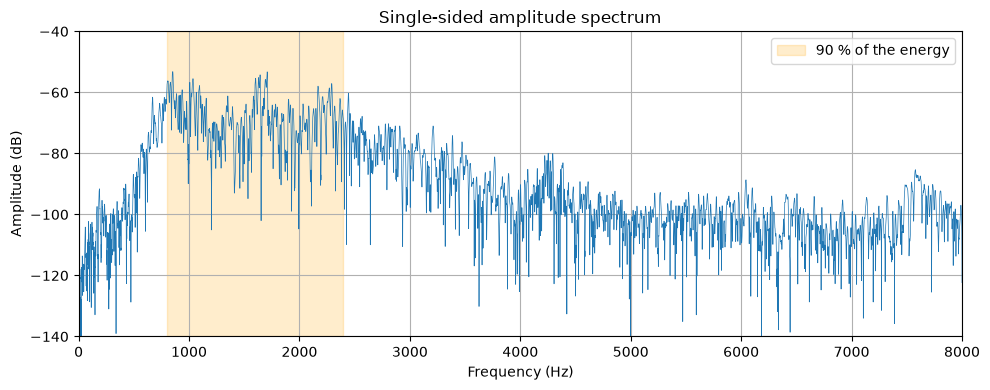

In [5]:
N = len(y)
Y = np.abs(np.fft.rfft(y)) / N
Y[1:-1] *= 2
f = np.fft.rfftfreq(N, 1/FS)

power = Y**2
cum = np.cumsum(power) / power.sum()
f05, f95 = f[np.searchsorted(cum, 0.05)], f[np.searchsorted(cum, 0.95)]
print(f'Strongest spectral line: {f[Y.argmax()]:.0f} Hz')
print(f'90 % of the energy lies between {f05:.0f} Hz and {f95:.0f} Hz')

bands = [(0, 500), (500, 1000), (1000, 2000), (2000, 4000), (4000, 8000)]
rows = []
for lo, hi in bands:
    share = 100 * power[(f >= lo) & (f < hi)].sum() / power.sum()
    rows.append((lo, hi, share))
    print(f'{lo:5d} - {hi:5d} Hz: {share:5.1f} % of the energy')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(f, 20*np.log10(Y + 1e-12), linewidth=0.5)
ax.axvspan(f05, f95, color='orange', alpha=0.2, label='90 % of the energy')
ax.set(title='Single-sided amplitude spectrum', xlabel='Frequency (Hz)', ylabel='Amplitude (dB)',
       xlim=(0, FS/2), ylim=(-140, -40))
ax.grid(True); ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / 'spectrum.png', dpi=150)
plt.show()
plt.close(fig)

## 5. Spectrograms with window lengths 512 and 2048

Both spectrograms use the same 16 kHz audio, a Hann window, a hop of 160 samples (10 ms) and the same colour range. Only the window length changes.

Window  512:  32.0 ms long, frequency bin spacing  31.25 Hz, 257 bins x 501 frames
Window 2048: 128.0 ms long, frequency bin spacing   7.81 Hz, 1025 bins x 501 frames


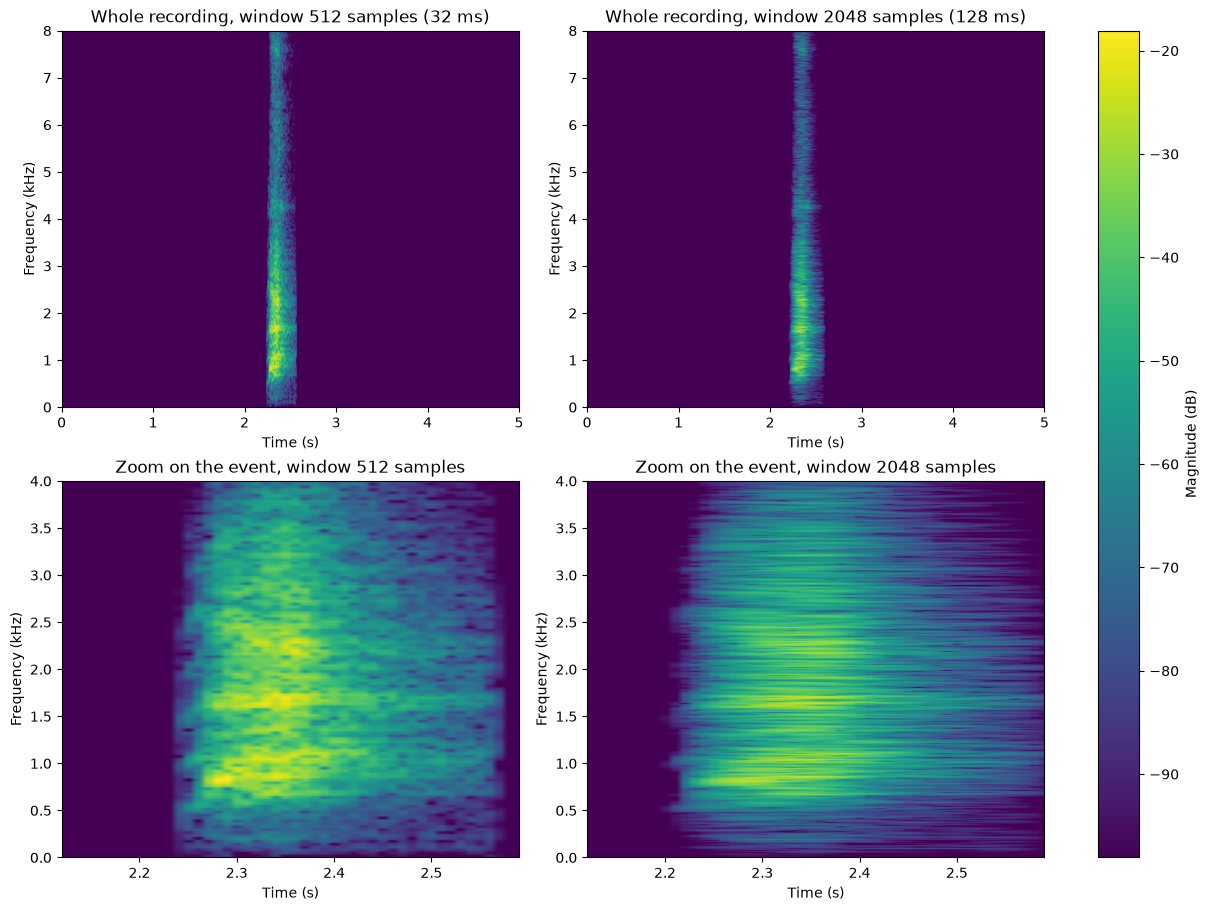

In [6]:
specs = {}
for n in WINDOWS:
    ff, tt, Z = stft(y, fs=FS, window='hann', nperseg=n, noverlap=n - HOP, boundary='zeros', padded=True)
    specs[n] = (ff, tt, 20*np.log10(np.abs(Z) + 1e-10))
    print(f'Window {n:4d}: {1000*n/FS:5.1f} ms long, frequency bin spacing {FS/n:6.2f} Hz, '
          f'{Z.shape[0]} bins x {Z.shape[1]} frames')

top = max(S.max() for _, _, S in specs.values())
vmin, vmax = top - 80, top

fig, ax = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for col, n in enumerate(WINDOWS):
    ff, tt, S = specs[n]
    ext = [tt[0], tt[-1], ff[0]/1000, ff[-1]/1000]
    im = ax[0, col].imshow(S, origin='lower', aspect='auto', extent=ext, vmin=vmin, vmax=vmax)
    ax[0, col].set(title=f'Whole recording, window {n} samples ({1000*n/FS:.0f} ms)',
                   xlabel='Time (s)', ylabel='Frequency (kHz)')
    ax[1, col].imshow(S, origin='lower', aspect='auto', extent=ext, vmin=vmin, vmax=vmax)
    ax[1, col].set(title=f'Zoom on the event, window {n} samples',
                   xlabel='Time (s)', ylabel='Frequency (kHz)',
                   xlim=(t0 - 0.15, t1 + 0.15), ylim=(0, 4))
fig.colorbar(im, ax=ax, label='Magnitude (dB)')
fig.savefig(RESULTS / 'spectrogram_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

## 6. How long does the event look in each spectrogram?

For each window length, the level in the 500–4000 Hz band is followed over time. The event length is the time during which this level is within 20 dB of its maximum. The number of spectral peaks in the loudest frame shows how much frequency detail each window resolves.

In [7]:
from scipy.signal import find_peaks

summary = []
for n in WINDOWS:
    ff, tt, S = specs[n]
    band = (ff >= 500) & (ff <= 4000)
    level = 10*np.log10(np.mean(10**(S[band]/10), axis=0))
    on = tt[level > level.max() - 20]
    frame = S[band][:, level.argmax()]
    peaks, _ = find_peaks(frame, prominence=10)
    summary.append((n, 1000*n/FS, FS/n, on.min(), on.max(), on.max() - on.min(), len(peaks)))
    print(f'Window {n:4d}: event visible from {on.min():.2f} s to {on.max():.2f} s '
          f'({on.max()-on.min():.2f} s), {len(peaks)} separate spectral peaks in the loudest frame')

with open(RESULTS / 'results_table.csv', 'w') as fh:
    fh.write('window_samples,window_ms,bin_spacing_hz,event_start_s,event_end_s,event_length_s,spectral_peaks\n')
    for row in summary:
        fh.write('%d,%.1f,%.2f,%.2f,%.2f,%.2f,%d\n' % row)
    fh.write('\n')
    fh.write('band_low_hz,band_high_hz,energy_percent\n')
    for lo, hi, share in rows:
        fh.write('%d,%d,%.1f\n' % (lo, hi, share))
print('Saved results/results_table.csv')

Window  512: event visible from 2.27 s to 2.43 s (0.16 s), 9 separate spectral peaks in the loudest frame
Window 2048: event visible from 2.24 s to 2.45 s (0.21 s), 43 separate spectral peaks in the loudest frame
Saved results/results_table.csv


## 7. Interpretation

**What the recording contains.** The clip is 5 seconds long, but the sound event is very short. The waveform shows one burst, and the level is above 10 % of its maximum only from 2.27 s to 2.44 s (0.17 s, 3.4 % of the recording). The spectrograms show a weaker tail of the same event until about 2.57 s. Before and after the event the recording is almost silent.

**Relevant time interval:** 2.27 s to 2.44 s, the single dog bark.

**Relevant frequency region:** about 0.8 kHz to 2.4 kHz. 90 % of the energy lies between 798 Hz and 2390 Hz, and the strongest line is at 852 Hz. Half of the energy (50.8 %) is in the 1 to 2 kHz band, and almost nothing is below 500 Hz (0.0 %) or above 4 kHz (0.2 %). In the zoomed spectrograms the bark has three strong regions, near 0.85 kHz, 1.65 kHz and 2.25 kHz.

**Effect of the window length.** Both spectrograms use the same audio, the same hop (160 samples, 10 ms) and the same colour range, so only the window length differs.

| Window | Length in time | Bin spacing | Event visible | Spectral peaks in the loudest frame |
|---|---|---|---|---|
| 512 samples | 32 ms | 31.25 Hz | 2.27 to 2.43 s (0.16 s) | 9 |
| 2048 samples | 128 ms | 7.81 Hz | 2.24 to 2.45 s (0.21 s) | 43 |

- With the **512-sample window** the start of the bark is a sharp vertical edge, and the measured length (0.16 s) agrees with the waveform (0.17 s). In frequency the picture is coarse: the three regions are broad blobs.
- With the **2048-sample window** the frequency detail is much finer. The broad regions split into many thin horizontal lines, and 43 separate peaks are found where the short window shows 9. The price is time resolution: each column now covers 128 ms, which is almost as long as the bark itself. The event appears to start earlier (2.24 s) and is smeared to 0.21 s, and the onset is no longer a sharp edge.

This is the time-frequency trade-off: a longer window gives narrower frequency bins but averages over more time. The hop is the same in both cases, so the number of columns is the same (501), but the columns of the long window overlap more and are not more precise in time.

**Which window is better here?** For this recording the 512-sample window is the better choice for locating the bark, because the event is short and its start and end matter. The 2048-sample window is better for studying the frequency content of the bark, for example the spacing of its spectral lines.

## 8. Limitation

The analysis is based on one recording with one single bark, so the time interval and the frequency region describe this clip and not dog sounds in general. Another dog, distance or microphone would give other values. The active interval also depends on the threshold I chose (10 % of the maximum level for the waveform, 20 dB below the maximum for the spectrograms). A different threshold moves the start and end times by some hundredths of a second. The count of spectral peaks is only a rough measure of frequency detail, because it also depends on the chosen prominence (10 dB).